In [16]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/keplersmachines/kepler-labelled-time-series-data/exoTest.csv
/kaggle/input/datasets/keplersmachines/kepler-labelled-time-series-data/exoTrain.csv


In [17]:
import matplotlib.pyplot as plt

DOSSIER = "/kaggle/input/datasets/kepler-labelled-time-series-data"
test = pd.read_csv("/kaggle/input/datasets/keplersmachines/kepler-labelled-time-series-data/exoTest.csv")
train = pd.read_csv("/kaggle/input/datasets/keplersmachines/kepler-labelled-time-series-data/exoTrain.csv")

print(train.shape, test.shape)
print(train["LABEL"].value_counts())
print(test["LABEL"].value_counts())

(5087, 3198) (570, 3198)
LABEL
1    5050
2      37
Name: count, dtype: int64
LABEL
1    565
2      5
Name: count, dtype: int64


In [18]:
X_train = train.drop(columns="LABEL").to_numpy()
y_train = (train["LABEL"] == 2).astype(int).to_numpy()
X_test = test.drop(columns="LABEL").to_numpy()
y_test = (test["LABEL"] == 2).astype(int).to_numpy()

print(X_train.shape, y_train.sum())
print(X_test.shape, y_test.sum())

(5087, 3197) 37
(570, 3197) 5


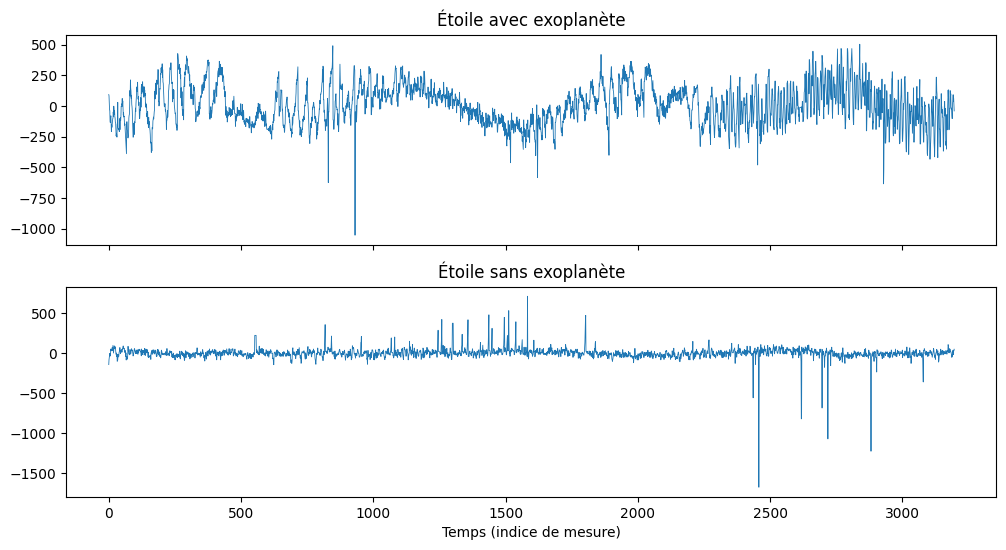

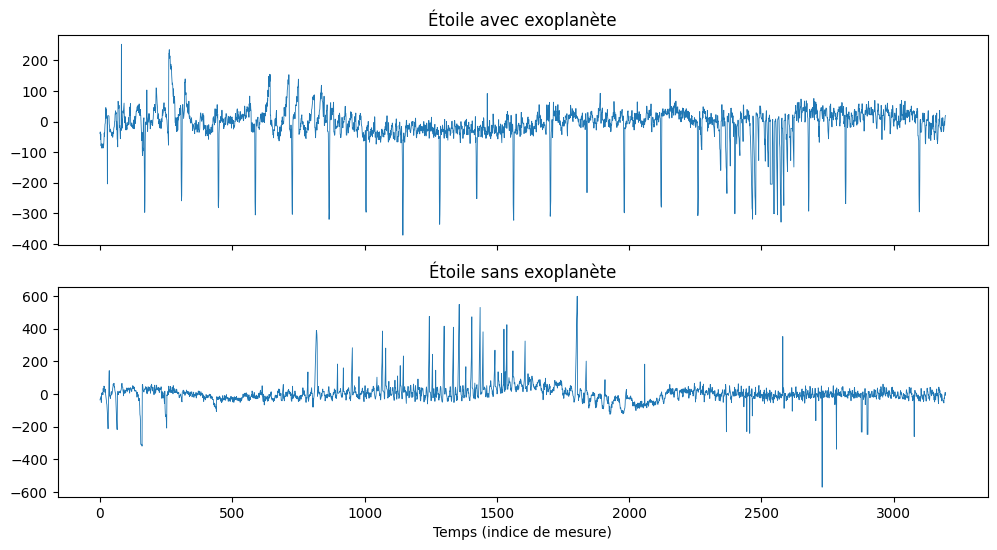

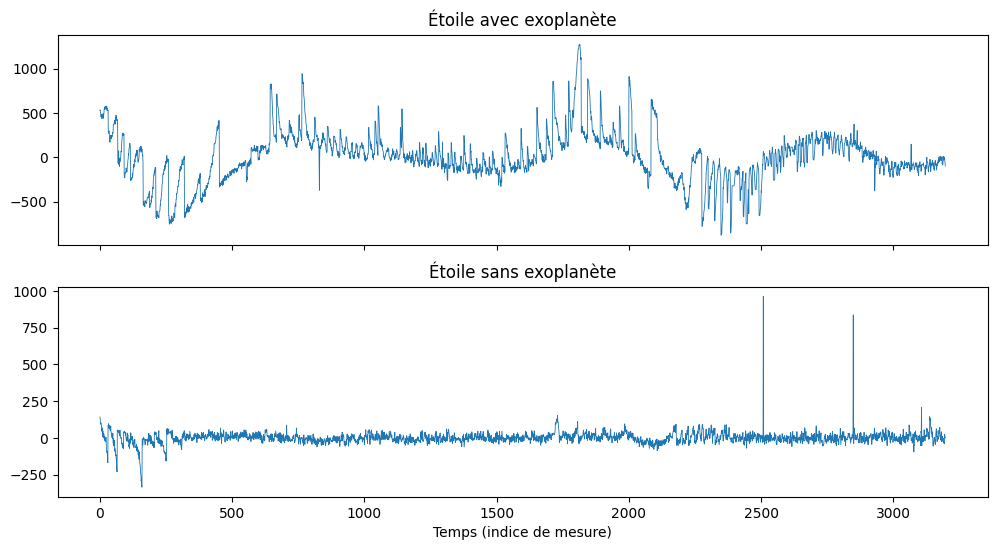

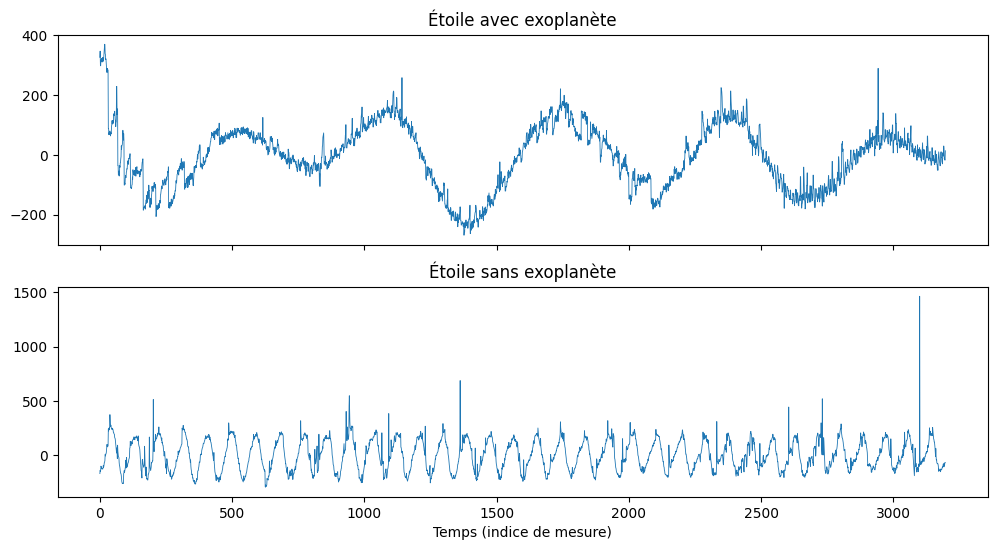

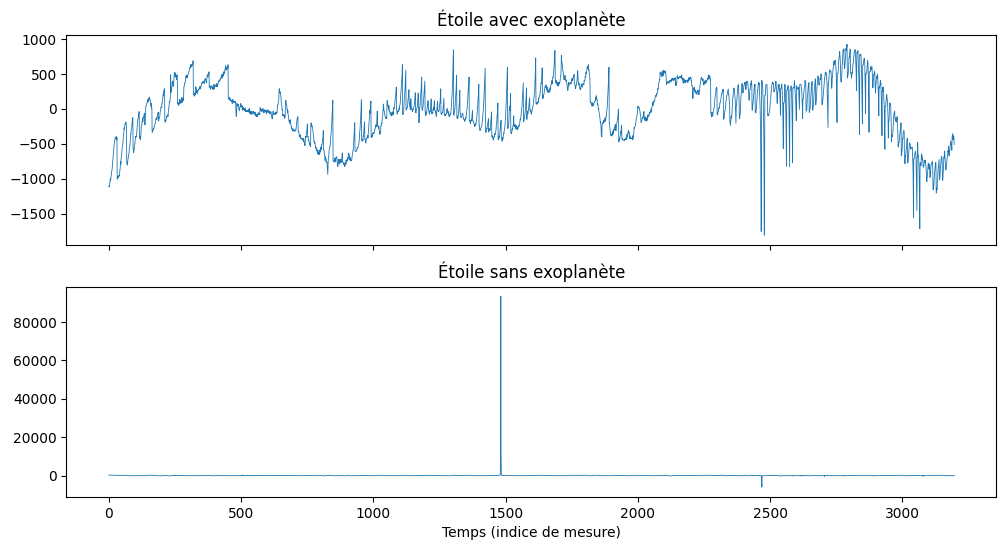

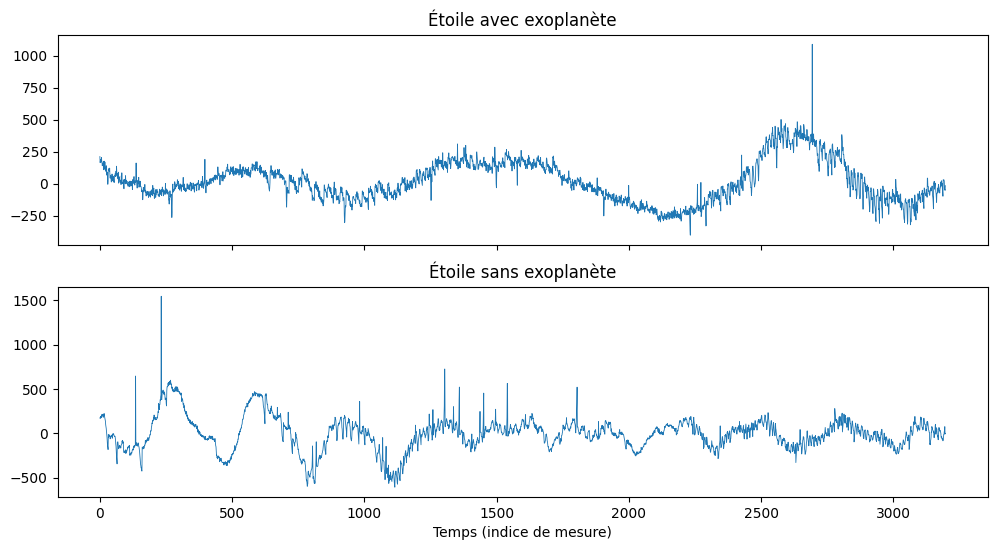

In [19]:
for i in range(6):
    i_planete = np.where(y_train == 1)[0][i]
    i_normale = np.where(y_train == 0)[0][i]
    fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
    axes[0].plot(X_train[i_planete], lw=0.6)
    axes[0].set_title("Étoile avec exoplanète")
    axes[1].plot(X_train[i_normale], lw=0.6)
    axes[1].set_title("Étoile sans exoplanète")
    axes[1].set_xlabel("Temps (indice de mesure)")
    plt.show()

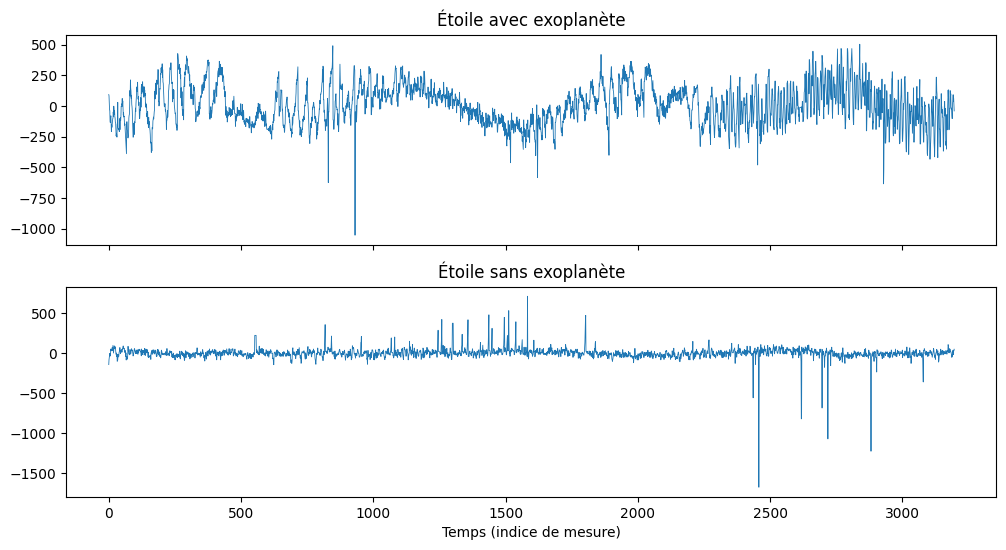

In [20]:
i_planete = np.where(y_train == 1)[0][0]
i_normale = np.where(y_train == 0)[0][0]

fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
axes[0].plot(X_train[i_planete], lw=0.6)
axes[0].set_title("Étoile avec exoplanète")
axes[1].plot(X_train[i_normale], lw=0.6)
axes[1].set_title("Étoile sans exoplanète")
axes[1].set_xlabel("Temps (indice de mesure)")
plt.show()

In [21]:
print(y_train.mean())
print(y_test.mean())
(y_test==0).mean()

0.007273442107332416
0.008771929824561403


np.float64(0.9912280701754386)

Indices planètes : [0 1 2 3 4]
Indices sans planète : [37 38 39 40 41]


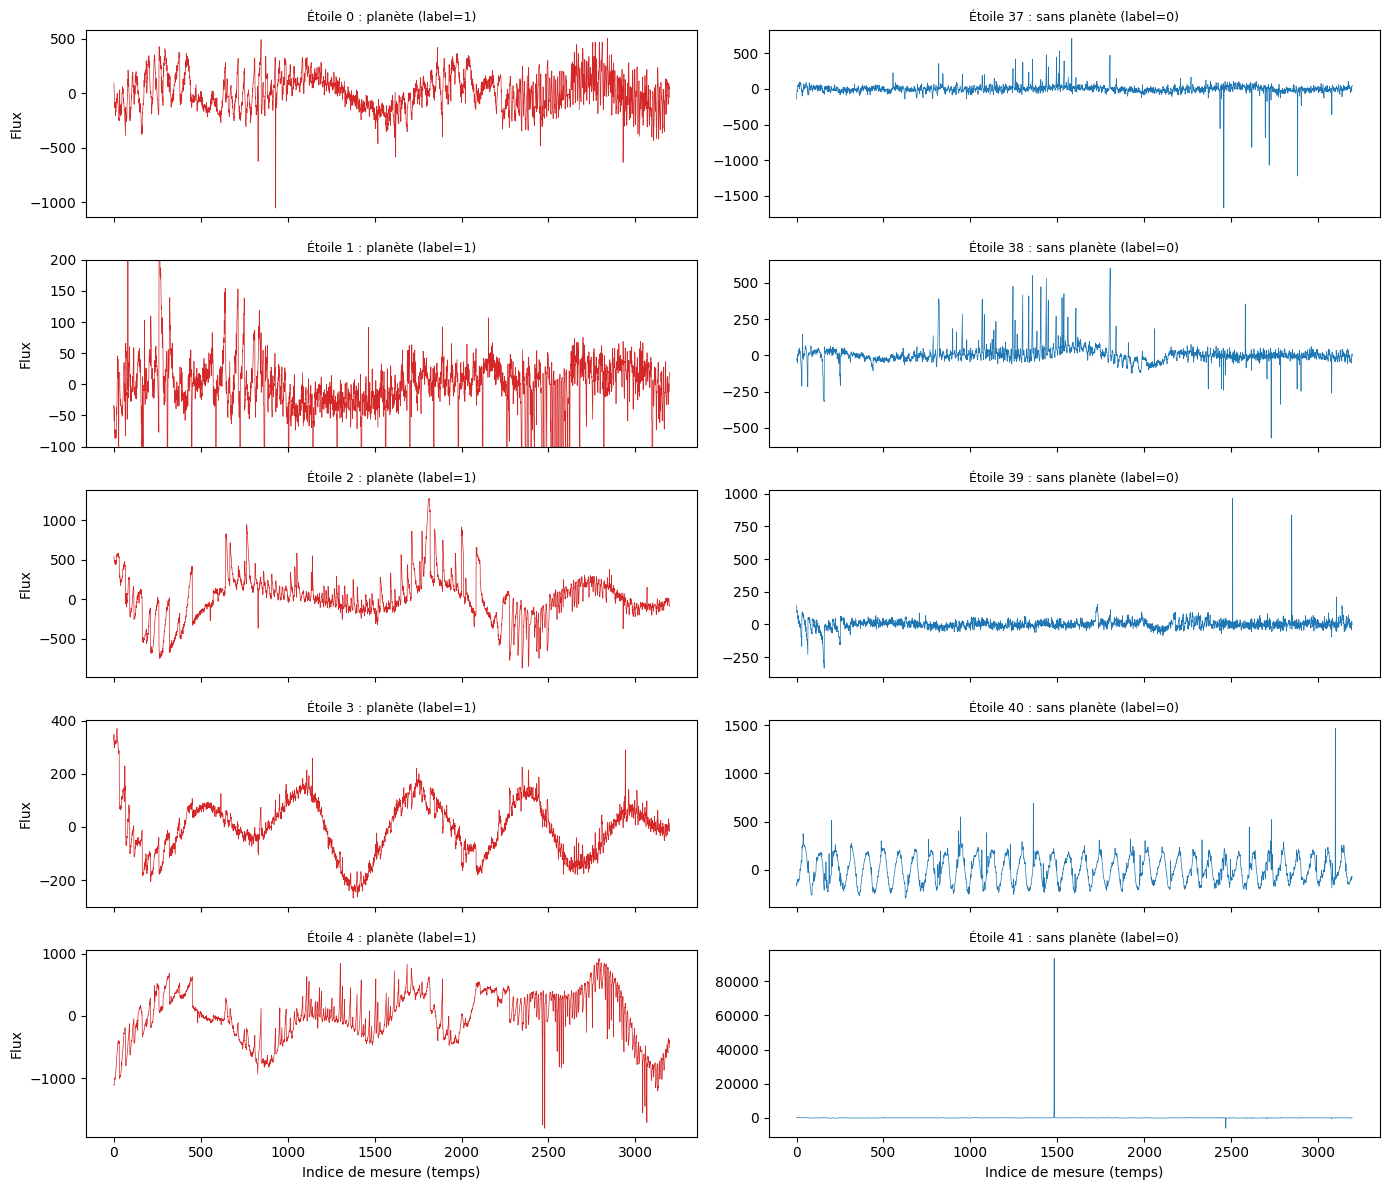

Étoile    0  label=1  min=     -1054.0  max=       504.5  écart-type=     160.7
Étoile    1  label=1  min=      -371.3  max=       252.6  écart-type=      60.0
Étoile    2  label=1  min=      -875.0  max=      1274.6  écart-type=     281.8
Étoile    3  label=1  min=      -268.4  max=       370.3  écart-type=     103.2
Étoile    4  label=1  min=     -1808.8  max=       924.3  écart-type=     407.1
Étoile   37  label=0  min=     -1671.6  max=       711.3  écart-type=      84.2
Étoile   38  label=0  min=      -571.0  max=       600.1  écart-type=      63.0
Étoile   39  label=0  min=      -334.8  max=       964.0  écart-type=      41.1
Étoile   40  label=0  min=      -292.4  max=      1464.3  écart-type=     140.2
Étoile   41  label=0  min=     -6054.6  max=     93373.9  écart-type=    1675.3


In [22]:
X = np.asarray(X_train)
y = np.asarray(y_train)

idx_pos = np.where(y == 1)[0][:5]
idx_neg = np.where(y == 0)[0][:5]
print("Indices planètes :", idx_pos)
print("Indices sans planète :", idx_neg)

fig, axes = plt.subplots(5, 2, figsize=(14, 12), sharex=True)

for k in range(5):
    i = idx_pos[k]
    axes[k, 0].plot(X[i], linewidth=0.5, color="tab:red")
    axes[k, 0].set_title(f"Étoile {i} : planète (label={y[i]})", fontsize=9)
    axes[k, 0].set_ylabel("Flux")
    if i == 1:
        axes[k, 0].set_ylim(-100, 200)

    j = idx_neg[k]
    axes[k, 1].plot(X[j], linewidth=0.5, color="tab:blue")
    axes[k, 1].set_title(f"Étoile {j} : sans planète (label={y[j]})", fontsize=9)

axes[4, 0].set_xlabel("Indice de mesure (temps)")
axes[4, 1].set_xlabel("Indice de mesure (temps)")
plt.tight_layout()
plt.show()

for i in list(idx_pos) + list(idx_neg):
    print(f"Étoile {i:4d}  label={y[i]}  min={X[i].min():12.1f}  max={X[i].max():12.1f}  écart-type={X[i].std():10.1f}")
    

(5087, 3197) (570, 3197)


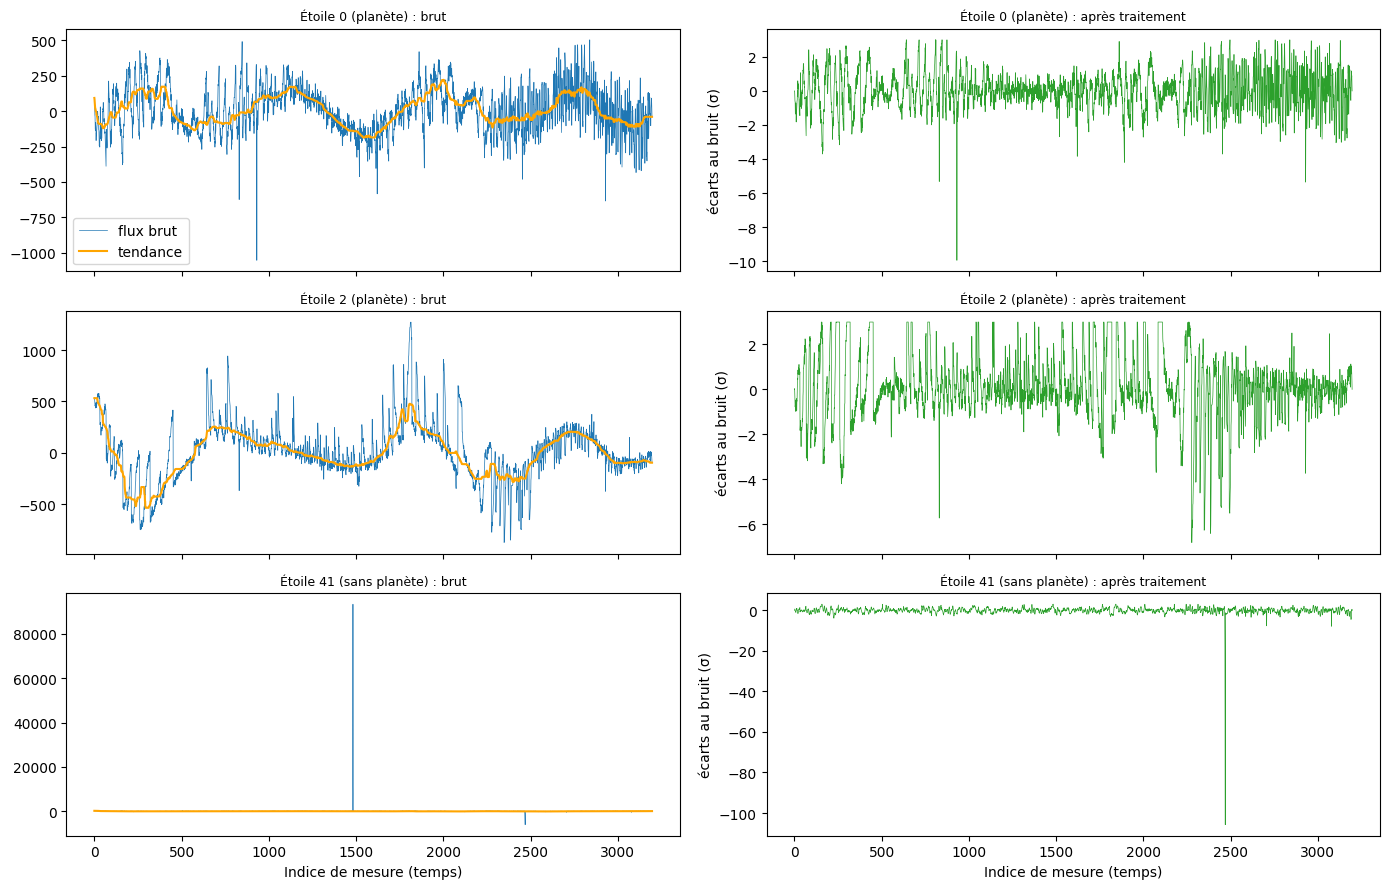

In [23]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import median_filter

def pretraiter(X, fenetre=101, seuil=3.0):
    X = np.asarray(X, dtype=float)
    tendance = median_filter(X, size=(1, fenetre), mode="nearest")
    residu = X - tendance
    centre = np.median(residu, axis=1, keepdims=True)
    mad = np.median(np.abs(residu - centre), axis=1, keepdims=True)
    sigma = 1.4826 * mad
    sigma[sigma == 0] = 1.0
    Z = (residu - centre) / sigma
    Z = np.minimum(Z, seuil)
    return Z, tendance


X_tr = np.asarray(X_train)
X_te = np.asarray(X_test)
y_tr = np.asarray(y_train)
y_te = np.asarray(y_test)

X_tr_p, tend_tr = pretraiter(X_tr)
X_te_p, tend_te = pretraiter(X_te)
print(X_tr_p.shape, X_te_p.shape)

etoiles = [0, 2, 41]
fig, axes = plt.subplots(3, 2, figsize=(14, 9), sharex=True)
for k, i in enumerate(etoiles):
    nom = "planète" if y_tr[i] == 1 else "sans planète"
    axes[k, 0].plot(X_tr[i], linewidth=0.5, label="flux brut")
    axes[k, 0].plot(tend_tr[i], linewidth=1.5, color="orange", label="tendance")
    axes[k, 0].set_title(f"Étoile {i} ({nom}) : brut", fontsize=9)
    axes[k, 1].plot(X_tr_p[i], linewidth=0.5, color="tab:green")
    axes[k, 1].set_title(f"Étoile {i} ({nom}) : après traitement", fontsize=9)
    axes[k, 1].set_ylabel("écarts au bruit (σ)")
axes[0, 0].legend()
axes[2, 0].set_xlabel("Indice de mesure (temps)")
axes[2, 1].set_xlabel("Indice de mesure (temps)")
plt.tight_layout()
plt.show(1)

In [24]:
import numpy as np
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, recall_score, precision_score,
                             confusion_matrix)
from scipy.stats import binomtest

X_tr = np.asarray(X_train)
X_te = np.asarray(X_test)
y_tr = np.asarray(y_train)
y_te = np.asarray(y_test)

baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_tr, y_tr)
y_pred = baseline.predict(X_te)

def resume(y_vrai, y_pred, nom):
    cm = confusion_matrix(y_vrai, y_pred, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()
    print(f"--- {nom} ---")
    print(f"Exactitude : {accuracy_score(y_vrai, y_pred):.3f}")
    print(f"Rappel     : {recall_score(y_vrai, y_pred, zero_division=0):.3f}")
    print(f"Précision  : {precision_score(y_vrai, y_pred, zero_division=0):.3f}")
    print(f"Matrice de confusion (lignes = vrai, colonnes = prédit) :\n{cm}")
    print(f"VN={tn}  FP={fp}  FN={fn}  VP={tp}\n")

resume(y_te, y_pred, "Baseline : toujours 'pas de planète'")

y_fictif = y_te.copy()
premier_positif = np.where(y_te == 1)[0][0]
y_fictif[premier_positif] = 0
y_fictif2 = y_te.copy()
for i in range(20):
    neg = np.where(y_te == 0 ) [0][i]
    y_fictif2[neg] = 1

resume(y_te, y_fictif2, "Modèle fictif : parfait sauf 20 fausses alarmes")

ic = binomtest(k=5, n=5).proportion_ci(confidence_level=0.95, method="exact")
print(f"Rappel 5/5 : intervalle de confiance à 95 % = [{ic.low:.3f}, {ic.high:.3f}]")

--- Baseline : toujours 'pas de planète' ---
Exactitude : 0.991
Rappel     : 0.000
Précision  : 0.000
Matrice de confusion (lignes = vrai, colonnes = prédit) :
[[565   0]
 [  5   0]]
VN=565  FP=0  FN=5  VP=0

--- Modèle fictif : parfait sauf 20 fausses alarmes ---
Exactitude : 0.965
Rappel     : 1.000
Précision  : 0.200
Matrice de confusion (lignes = vrai, colonnes = prédit) :
[[545  20]
 [  0   5]]
VN=545  FP=20  FN=0  VP=5

Rappel 5/5 : intervalle de confiance à 95 % = [0.478, 1.000]


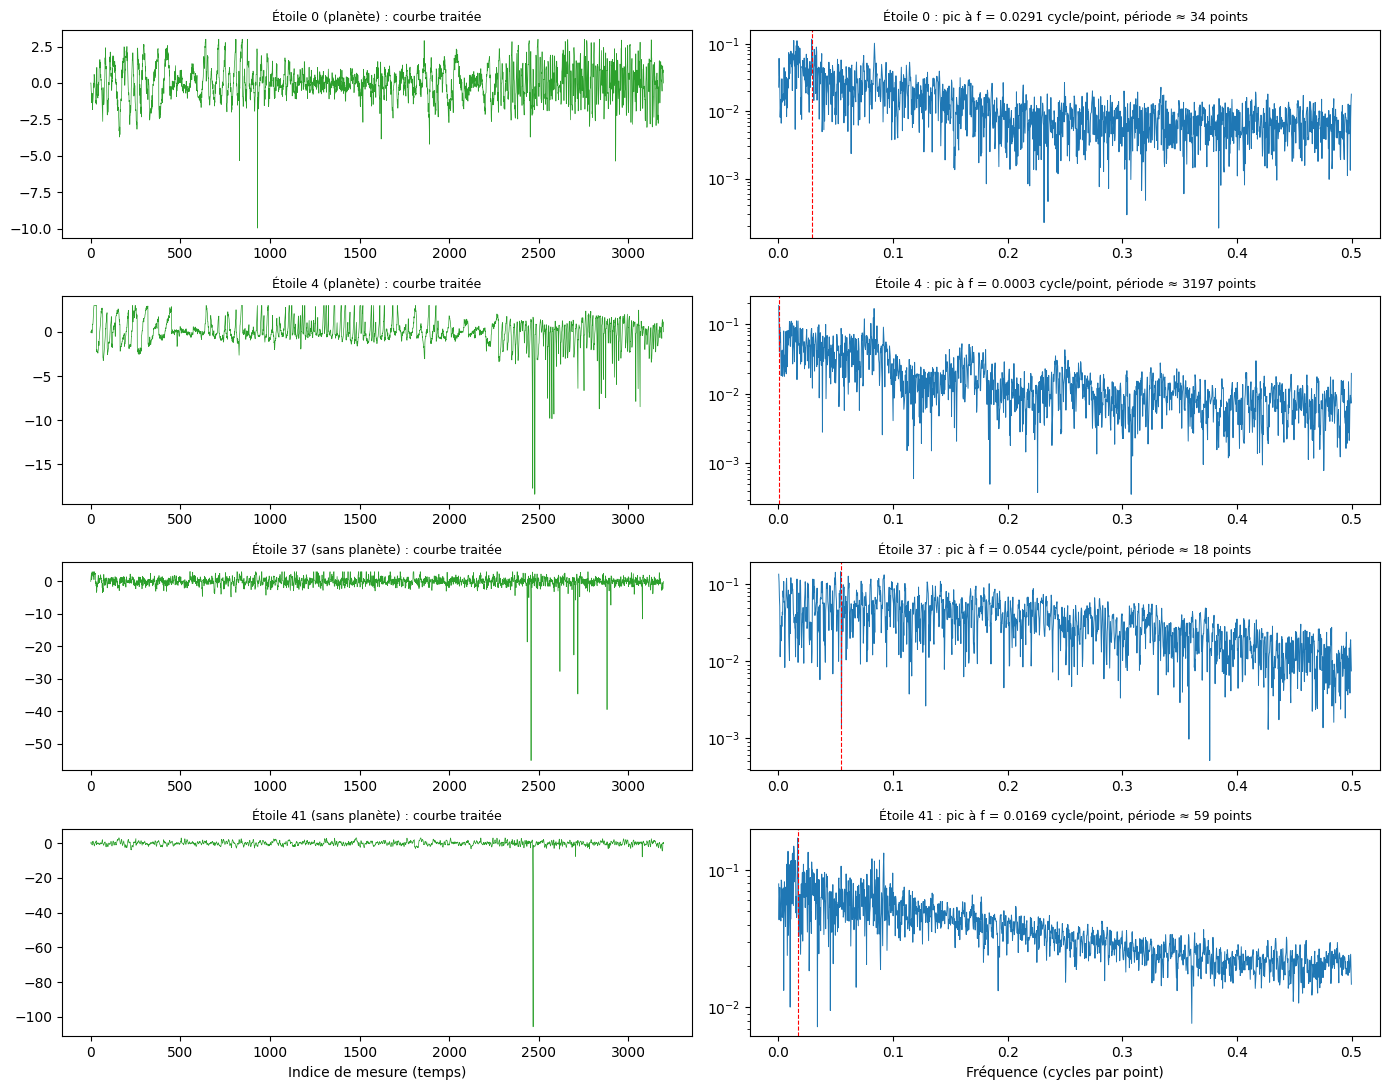

In [25]:
n = X_tr_p.shape[1]
spectre = np.abs(np.fft.rfft(X_tr_p, axis=1)) / n
freqs = np.fft.rfftfreq(n, d=1.0)

etoiles = [0, 4, 37, 41]
fig, axes = plt.subplots(len(etoiles), 2, figsize=(14, 11))
for k, i in enumerate(etoiles):
    nom = "planète" if y_tr[i] == 1 else "sans planète"
    axes[k, 0].plot(X_tr_p[i], linewidth=0.5, color="tab:green")
    axes[k, 0].set_title(f"Étoile {i} ({nom}) : courbe traitée", fontsize=9)

    axes[k, 1].plot(freqs[1:], spectre[i, 1:], linewidth=0.7)
    axes[k, 1].set_yscale("log")
    j = np.argmax(spectre[i, 1:]) + 1
    axes[k, 1].axvline(freqs[j], color="red", linestyle="--", linewidth=0.8)
    axes[k, 1].set_title(
        f"Étoile {i} : pic à f = {freqs[j]:.4f} cycle/point, période ≈ {1/freqs[j]:.0f} points",
        fontsize=9)
axes[-1, 0].set_xlabel("Indice de mesure (temps)")
axes[-1, 1].set_xlabel("Fréquence (cycles par point)")
plt.tight_layout()
plt.show()

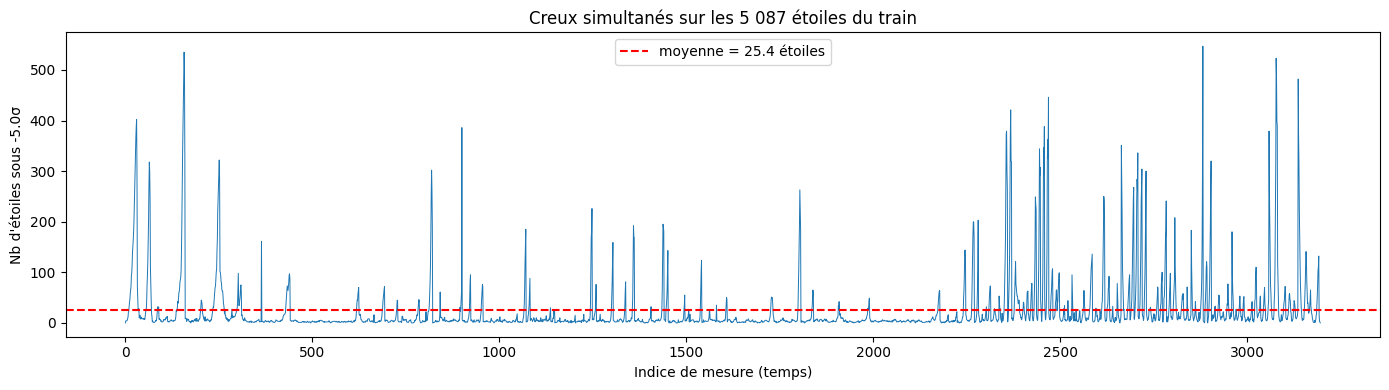

Instant | nb étoiles | % des planètes | % des non-planètes
   2882 |        547 |           0.0 % |             10.8 %
    157 |        535 |           0.0 % |             10.6 %
   3078 |        523 |           0.0 % |             10.4 %
    156 |        506 |           0.0 % |             10.0 %
    158 |        504 |           0.0 % |             10.0 %
   3079 |        486 |           0.0 % |              9.6 %
   3137 |        482 |           0.0 % |              9.5 %
    155 |        452 |           0.0 % |              9.0 %
   2469 |        446 |           0.0 % |              8.8 %
   2368 |        421 |           2.7 % |              8.3 %


In [26]:
seuil_creux = -5.0

creux = X_tr_p < seuil_creux
nb_par_instant = creux.sum(axis=0)
moyenne = nb_par_instant.mean()

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(nb_par_instant, linewidth=0.7)
ax.axhline(moyenne, color="red", linestyle="--", label=f"moyenne = {moyenne:.1f} étoiles")
ax.set_xlabel("Indice de mesure (temps)")
ax.set_ylabel(f"Nb d'étoiles sous {seuil_creux}σ")
ax.set_title("Creux simultanés sur les 5 087 étoiles du train")
ax.legend()
plt.tight_layout()
plt.show()

pos = (y_tr == 1)
neg = (y_tr == 0)
top = np.argsort(nb_par_instant)[::-1][:10]
print("Instant | nb étoiles | % des planètes | % des non-planètes")
for t in top:
    print(f"{t:7d} | {nb_par_instant[t]:10d} | "
          f"{100 * creux[pos, t].mean():13.1f} % | {100 * creux[neg, t].mean():16.1f} %")

193 instants suspects sur 3197
[  18   19   20   21   22   23   24   25   26   27   28   29   30   31
   60   61   62   63   64   65   66   67  149  150  151  152  153  154
  155  156  157  158  159  244  245  246  247  248  249  250  251  252
  364  816  817  818  819  820  821  900 1069 1070 1071 1246 1247 1248
 1303 1304 1358 1359 1360 1361 1437 1438 1439 1440 1450 1451 1541 1801
 1802 1803 1804 1805 1806 2245 2246 2247 2266 2267 2268 2269 2270 2280
 2281 2353 2354 2355 2356 2357 2358 2359 2365 2366 2367 2368 2369 2370
 2381 2433 2434 2435 2436 2443 2444 2445 2446 2447 2455 2456 2457 2458
 2465 2466 2467 2468 2469 2479 2480 2583 2584 2585 2586 2615 2616 2617
 2618 2619 2664 2665 2666 2667 2694 2695 2696 2697 2704 2705 2706 2707
 2708 2716 2717 2718 2719 2728 2729 2730 2781 2782 2783 2784 2807 2808
 2851 2852 2880 2881 2882 2891 2892 2893 2901 2902 2903 2904 2960 3024
 3025 3059 3060 3061 3062 3075 3076 3077 3078 3079 3080 3081 3082 3137
 3138 3139 3140 3141 3142 3157 3158 3159 3190 

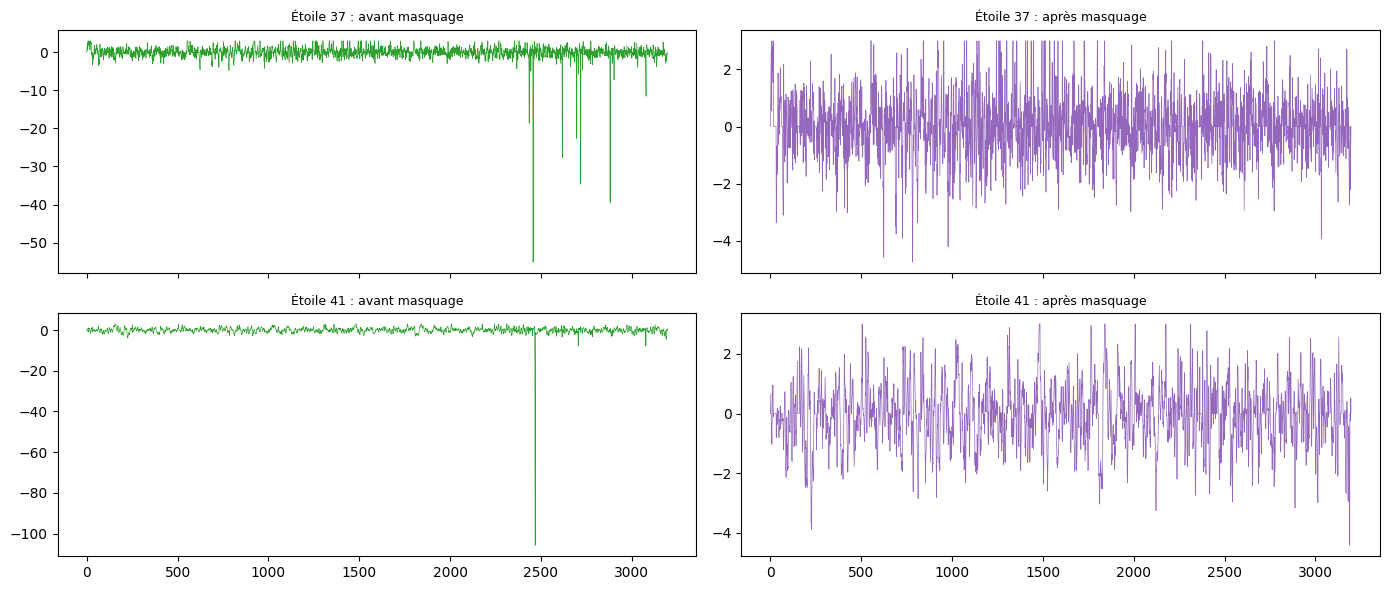

In [27]:
frac_creux = (X_tr_p < -5.0).mean(axis=0)
seuil_frac = 0.02
instants_suspects = np.where(frac_creux > seuil_frac)[0]
print(f"{len(instants_suspects)} instants suspects sur {X_tr_p.shape[1]}")
print(instants_suspects)

X_tr_m = X_tr_p.copy()
X_te_m = X_te_p.copy()
X_tr_m[:, instants_suspects] = 0.0
X_te_m[:, instants_suspects] = 0.0

def frac_avec_creux(X, masque_classe, seuil=-5.0):
    a_un_creux = (X[masque_classe] < seuil).any(axis=1)
    return a_un_creux.mean()

for nom, X in [("avant masquage", X_tr_p), ("après masquage", X_tr_m)]:
    print(f"{nom} : étoiles avec au moins un creux < -5σ -> "
          f"planètes {100 * frac_avec_creux(X, y_tr == 1):.1f} %, "
          f"non-planètes {100 * frac_avec_creux(X, y_tr == 0):.1f} %")

fig, axes = plt.subplots(2, 2, figsize=(14, 6), sharex=True)
for k, i in enumerate([37, 41]):
    axes[k, 0].plot(X_tr_p[i], linewidth=0.5, color="tab:green")
    axes[k, 0].set_title(f"Étoile {i} : avant masquage", fontsize=9)
    axes[k, 1].plot(X_tr_m[i], linewidth=0.5, color="tab:purple")
    axes[k, 1].set_title(f"Étoile {i} : après masquage", fontsize=9)
plt.tight_layout()
plt.show()

(5087, 6) (570, 6)
                 médiane sans planète  médiane planète
creux_min                   -4.551424        -7.084240
nb_points_sous3             13.000000        58.000000
nb_points_sous5              0.000000        12.000000
serie_max_sous3              3.000000         8.000000
nb_series_sous3              1.000000         7.000000
asymetrie                   -0.001914        -0.674379


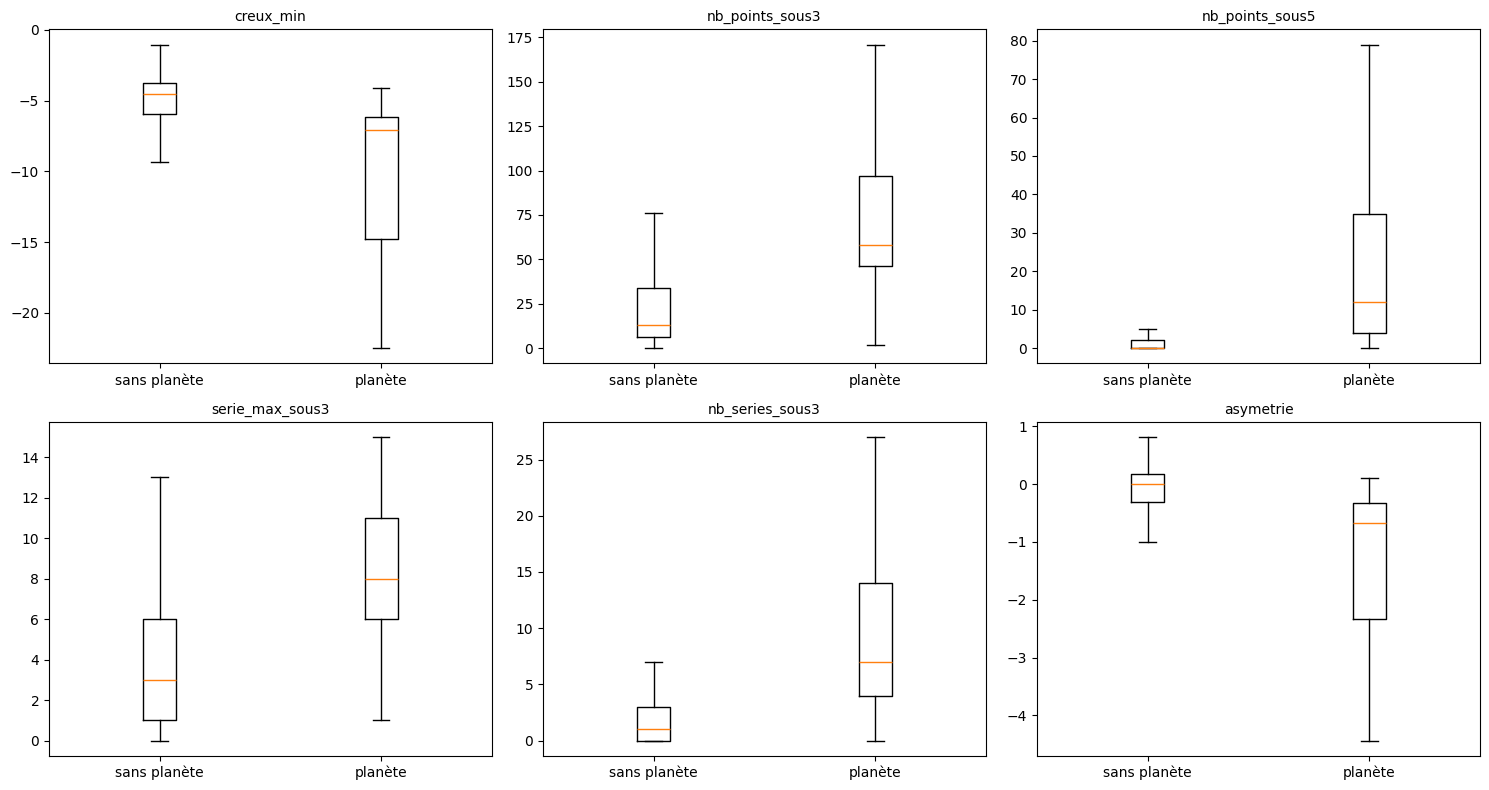

In [28]:
import pandas as pd
from scipy.stats import skew


def plus_longue_serie(b):
    p = np.concatenate([[0], b.astype(int), [0]])
    d = np.diff(p)
    debuts = np.where(d == 1)[0]
    fins = np.where(d == -1)[0]
    return int((fins - debuts).max()) if len(debuts) > 0 else 0

def nb_series(b, longueur_min=3):
    p = np.concatenate([[0], b.astype(int), [0]])
    d = np.diff(p)
    longueurs = np.where(d == -1)[0] - np.where(d == 1)[0]
    return int((longueurs >= longueur_min).sum())

def variables(X):
    sous3 = X < -3.0
    return pd.DataFrame({
        "creux_min":       X.min(axis=1),
        "nb_points_sous3": sous3.sum(axis=1),
        "nb_points_sous5": (X < -5.0).sum(axis=1),
        "serie_max_sous3": [plus_longue_serie(b) for b in sous3],
        "nb_series_sous3": [nb_series(b) for b in sous3],
        "asymetrie":       skew(X, axis=1),
    })

F_tr = variables(X_tr_m)
F_te = variables(X_te_m)
print(F_tr.shape, F_te.shape)

print(F_tr.groupby(y_tr).median().T.rename(columns={0: "médiane sans planète", 1: "médiane planète"}))

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), F_tr.columns):
    ax.boxplot([F_tr.loc[y_tr == 0, col], F_tr.loc[y_tr == 1, col]],
               tick_labels=["sans planète", "planète"], showfliers=False)
    ax.set_title(col, fontsize=10)
plt.tight_layout()
plt.show()

In [29]:
from sklearn.metrics import roc_auc_score

rng = np.random.default_rng(42)
F_tr_aug = F_tr.copy()
F_tr_aug["hasard"] = rng.normal(size=len(F_tr))

sens = {"creux_min": -1, "asymetrie": -1}

idx_pos = np.where(y_tr == 1)[0]
idx_neg = np.where(y_tr == 0)[0]
n_boot = 1000

resultats = []
for col in F_tr_aug.columns:
    score = sens.get(col, 1) * F_tr_aug[col].to_numpy()
    auc = roc_auc_score(y_tr, score)
    aucs_boot = []
    for _ in range(n_boot):
        ech = np.concatenate([rng.choice(idx_pos, size=len(idx_pos), replace=True),
                              rng.choice(idx_neg, size=len(idx_neg), replace=True)])
        aucs_boot.append(roc_auc_score(y_tr[ech], score[ech]))
    bas, haut = np.percentile(aucs_boot, [2.5, 97.5])
    resultats.append((col, auc, bas, haut))

tableau = pd.DataFrame(resultats, columns=["variable", "AUC", "IC95_bas", "IC95_haut"])
print(tableau.sort_values("AUC", ascending=False).round(3).to_string(index=False))

       variable   AUC  IC95_bas  IC95_haut
      asymetrie 0.859     0.811      0.899
nb_points_sous3 0.839     0.780      0.884
      creux_min 0.836     0.780      0.886
nb_series_sous3 0.832     0.778      0.876
nb_points_sous5 0.812     0.739      0.877
serie_max_sous3 0.778     0.723      0.822
         hasard 0.530     0.447      0.612


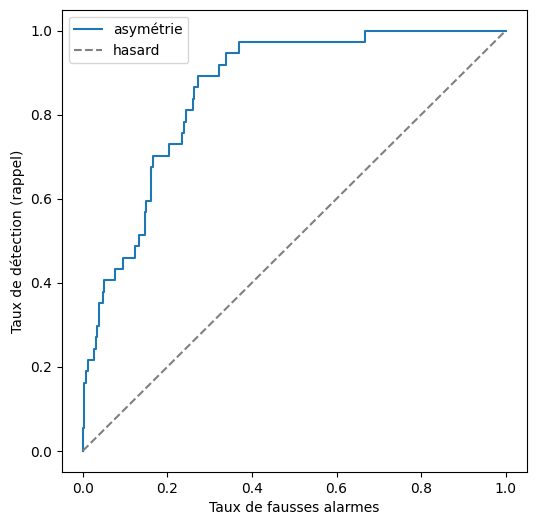

Rappel 0.81 -> taux de fausses alarmes 0.244
Soit 30 planètes trouvées pour 1233 fausses alarmes, précision 0.024


In [30]:
from sklearn.metrics import roc_curve

fpr, tpr, seuils = roc_curve(y_tr, -F_tr["asymetrie"])

plt.figure(figsize=(6, 6))
plt.plot(fpr, tpr, label="asymétrie")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="hasard")
plt.xlabel("Taux de fausses alarmes")
plt.ylabel("Taux de détection (rappel)")
plt.legend()
plt.show()

i = np.argmax(tpr >= 0.8)
vp = tpr[i] * len(idx_pos)
fp = fpr[i] * len(idx_neg)
print(f"Rappel {tpr[i]:.2f} -> taux de fausses alarmes {fpr[i]:.3f}")
print(f"Soit {vp:.0f} planètes trouvées pour {fp:.0f} fausses alarmes, précision {vp / (vp + fp):.3f}")